# ChurnGuard — Exploratory Data Analysis

Dataset: IBM Telco Customer Churn (7,043 customers). Target: `Churn` (Yes/No).

**Tasks covered:**
1. Load with Pandas
2. Shape + column names
3. Dtypes + descriptive statistics
4. Missing values + duplicated rows
5. Convert `TotalCharges` to numeric
6. Handle blank/invalid `TotalCharges`
7. Churn target distribution
8. Churn visualizations (contract, tenure, monthly charges, etc.)
9. Patterns + business implications

In [1]:
# Setup — from the project root in Jupyter this path note matters:
# if your kernel cwd is notebooks/, go up one level to see data/.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
CSV = ROOT / "data" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

sns.set_theme(style="whitegrid")
df = pd.read_csv(CSV)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Shape and columns

In [2]:
print("Shape:", df.shape)
print("Columns:", list(df.columns))

Shape: (7043, 21)
Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


## 3. Dtypes and descriptive statistics

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Key observation:** `TotalCharges` is `object` (text), not numeric — pandas couldn't
coerce it because some rows contain blank strings `" "`. Those rows show 0 NaN here
(they're whitespace strings, not NULL). We handle that in steps 5–6.

## 4. Missing values and duplicated rows

In [5]:
print("Standard NaNs per column:")
nan_counts = df.isnull().sum()[df.isnull().sum() > 0]
print(nan_counts if len(nan_counts) else "none")

print("\nDuplicated rows:", df.duplicated().sum())
print("Duplicated customerID:", df["customerID"].duplicated().sum())

Standard NaNs per column:
none

Duplicated rows: 0
Duplicated customerID: 0


## 5–6. Convert TotalCharges to numeric and handle blanks

In [6]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
blank_rows = df[df["TotalCharges"].isna()]
print(f"Rows with invalid/blank TotalCharges: {len(blank_rows)}")
blank_rows[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Rows with invalid/blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [7]:
# All blank rows have tenure == 0: brand-new customers, no charge record yet.
# Decision: drop them (<0.2% of data). Keeping them would demand imputation;
# for this project the cleaner choice is removal (documented in preprocessing.py).
print("Tenure of blank rows:", blank_rows["tenure"].unique())
df = df.dropna(subset=["TotalCharges"]).reset_index(drop=True)
print("Shape after cleaning:", df.shape)

Tenure of blank rows: [0]
Shape after cleaning: (7032, 21)


## 7. Target distribution

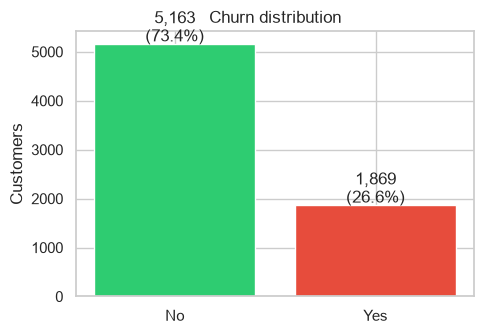

Churn rate: 0.2658
-> Moderately imbalanced (~73/27). Accuracy alone will be misleading;
   we'll use class_weight='balanced' and F1/ROC-AUC/PR-AUC in training.


In [8]:
fig, ax = plt.subplots(figsize=(5, 3.5))
counts = df["Churn"].value_counts()
ax.bar(counts.index, counts.values, color=["#2ecc71", "#e74c3c"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 50, f"{v:,}\n({v/len(df):.1%})", ha="center")
ax.set_title("Churn distribution")
ax.set_ylabel("Customers")
plt.tight_layout(); plt.show()
print("Churn rate:", round((df["Churn"] == "Yes").mean(), 4))
print("-> Moderately imbalanced (~73/27). Accuracy alone will be misleading;")
print("   we'll use class_weight='balanced' and F1/ROC-AUC/PR-AUC in training.")

## 8. Visualizations: churn by key features

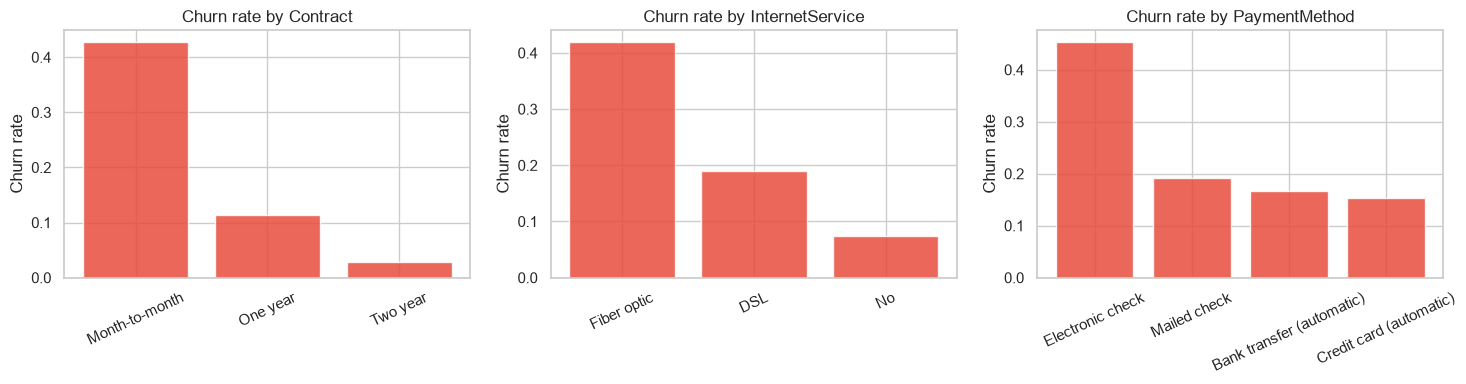

In [9]:
def churn_rate_by(col, order=None):
    return df.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    rates = churn_rate_by(col).sort_values(ascending=False)
    ax.bar(rates.index, rates.values, color="#e74c3c", alpha=0.85)
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

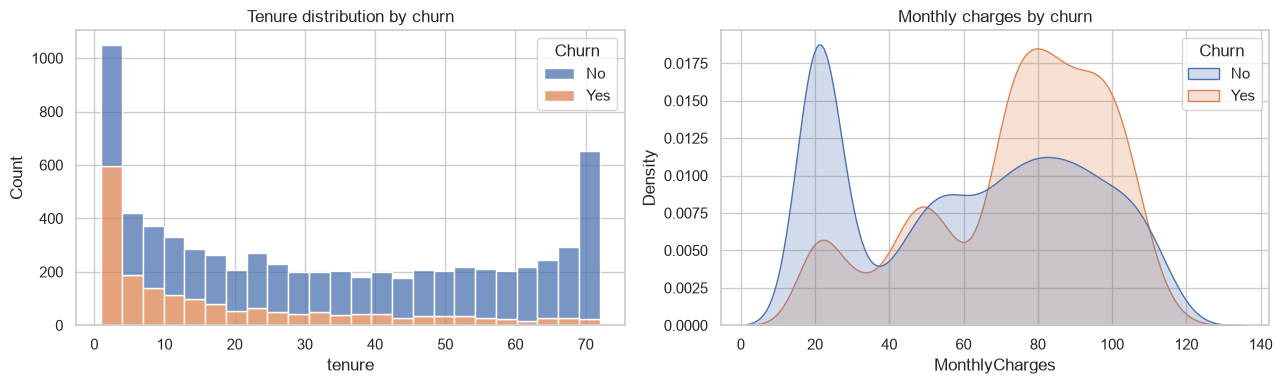

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=24, multiple="stack", ax=axes[0])
axes[0].set_title("Tenure distribution by churn")
sns.kdeplot(data=df, x="MonthlyCharges", hue="Churn", common_norm=False, fill=True, ax=axes[1])
axes[1].set_title("Monthly charges by churn")
plt.tight_layout(); plt.show()

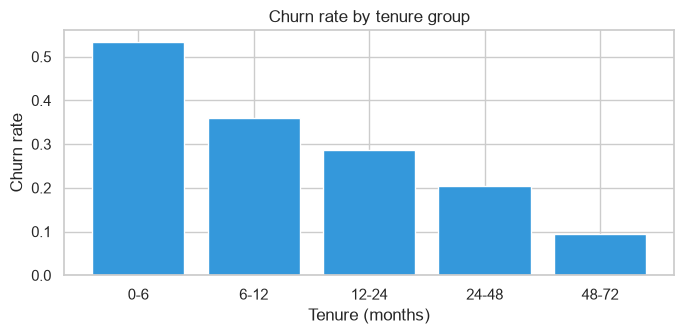

tenure_group
0-6      0.533
6-12     0.359
12-24    0.287
24-48    0.204
48-72    0.095
Name: Churn, dtype: float64


In [11]:
# Churn rate by tenure group — quantifies the "new customers leave most" pattern
bins = [0, 6, 12, 24, 48, 72]
labels = ["0-6", "6-12", "12-24", "24-48", "48-72"]
df2 = df.copy()
df2["tenure_group"] = pd.cut(df2["tenure"], bins=bins, labels=labels)
rate = df2.groupby("tenure_group", observed=True)["Churn"].apply(lambda s: (s == "Yes").mean())

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(rate.index.astype(str), rate.values, color="#3498db")
ax.set_xlabel("Tenure (months)"); ax.set_ylabel("Churn rate")
ax.set_title("Churn rate by tenure group")
plt.tight_layout(); plt.show()
print(rate.round(3))

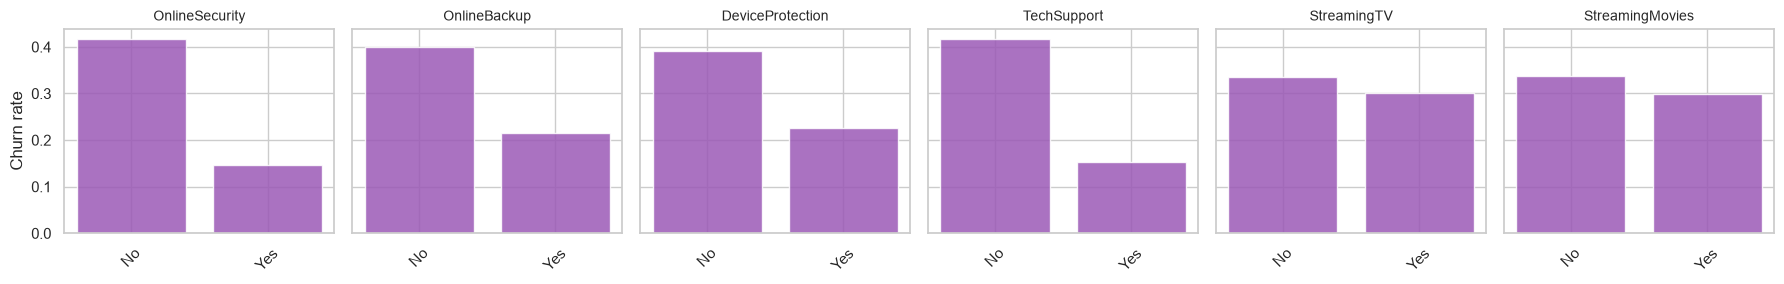

In [12]:
# Add-on services effect (among internet customers only)
internet = df[df["InternetService"] != "No"]
add_ons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
fig, axes = plt.subplots(1, 6, figsize=(18, 3), sharey=True)
for ax, col in zip(axes, add_ons):
    r = (internet.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean()))
    ax.bar(r.index.astype(str), r.values, color="#9b59b6", alpha=0.85)
    ax.set_title(col, fontsize=10)
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Churn rate")
plt.tight_layout(); plt.show()

## 9. Patterns and business implications

| Pattern (from the charts above) | Business implication |
|---|---|
| Month-to-month contracts churn far more than 1/2-year contracts | Push annual conversions; month-to-month is the biggest structural risk |
| Churn is highest in the first 6–12 months of tenure | Onboarding/early-experience programs matter most; retention offers for low-tenure customers |
| Fiber-optic customers churn more than DSL | Investigate fiber pricing/quality perception before it drives exits |
| Electronic-check payers churn more | Auto-payment (card/bank) correlates with stickiness — incentivize it |
| No OnlineSecurity/TechSupport → higher churn | Bundle protection services at sign-up; they correlate with retention |
| Higher monthly charges → higher churn | Price-sensitive segments need targeted offers |

These empirically observed patterns are exactly what the trained model should rediscover —
the Logistic Regression coefficients in `artifacts/metrics.json` (tenure, Contract_Month-to-month
being top signals) confirm they carry through to the model.